In [31]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [32]:
df = pd.read_csv("/content/ArtificialPatientTreatment.csv")

In [33]:
df.head(20)

,patient,action,org:resource,DateTime
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11
1,patient 0,Blood test,Lab,2017-01-02 12:47:33
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09
5,patient 0,Final consult,Dr. Ben,2017-01-09 08:29:28
6,patient 1,First consult,Dr. Anna,2017-01-02 12:50:35
7,patient 1,Physical test,Nurse Jesse,2017-01-02 13:59:14
8,patient 1,Blood test,Lab,2017-01-02 14:20:19
9,patient 1,X-ray scan,Team 1,2017-01-06 09:13:40


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   patient        690 non-null    object
 1    action        690 non-null    object
 2    org:resource  690 non-null    object
 3    DateTime      690 non-null    object
dtypes: object(4)
memory usage: 21.7+ KB


In [35]:
df.describe()

,patient,action,org:resource,DateTime
count,690,690,690,690
unique,100,8,13,690
top,patient 1,First consult,Dr. Anna,2017-01-02 11:40:11
freq,7,100,158,1


In [36]:
df.shape

(690, 4)

In [37]:
df.isnull().sum()

,0
patient,0
action,0
org:resource,0
DateTime,0


In [38]:
df.columns = df.columns.str.strip()

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   patient       690 non-null    object
 1   action        690 non-null    object
 2   org:resource  690 non-null    object
 3   DateTime      690 non-null    object
dtypes: object(4)
memory usage: 21.7+ KB


In [40]:
df.head()

,patient,action,org:resource,DateTime
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11
1,patient 0,Blood test,Lab,2017-01-02 12:47:33
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09


In [41]:
df['DateTimeClean'] = pd.to_datetime(df['DateTime'])

In [42]:
df.head()

,patient,action,org:resource,DateTime,DateTimeClean
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11,2017-01-02 11:40:11
1,patient 0,Blood test,Lab,2017-01-02 12:47:33,2017-01-02 12:47:33
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50,2017-01-02 12:53:50
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06,2017-01-02 16:21:06
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09,2017-01-05 13:23:09


In [43]:
df = df.sort_values(by=['patient','DateTimeClean'])

In [44]:
df.head()

,patient,action,org:resource,DateTime,DateTimeClean
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11,2017-01-02 11:40:11
1,patient 0,Blood test,Lab,2017-01-02 12:47:33,2017-01-02 12:47:33
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50,2017-01-02 12:53:50
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06,2017-01-02 16:21:06
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09,2017-01-05 13:23:09


In [45]:
df['NextActivity'] = df.groupby('patient')['action'].shift(-1)

In [46]:
df['NextActivity'] = df['NextActivity'].fillna('[END]')

In [47]:
df['NextActivity'].head(20)

,NextActivity
0,Blood test
1,Physical test
2,Second consult
3,Surgery
4,Final consult
5,[END]
6,Physical test
7,Blood test
8,X-ray scan
9,Second consult


In [48]:
df['Next_Timestamp'] = df.groupby('patient')['DateTimeClean'].shift(-1)

In [49]:
df['Next_Timestamp'] = df['Next_Timestamp'].fillna('[END]')

In [50]:
next_timestamp_raw = df.groupby('patient')['DateTimeClean'].shift(-1)
df['Duration_Minutes'] = (next_timestamp_raw - df['DateTimeClean']).dt.total_seconds() / 60

In [51]:
df['Transition'] = df['action']+"->"+df['NextActivity']

In [52]:
df['Transition'].head(20)

,Transition
0,First consult-> Blood test
1,Blood test-> Physical test
2,Physical test-> Second consult
3,Second consult-> Surgery
4,Surgery-> Final consult
5,Final consult->[END]
6,First consult-> Physical test
7,Physical test-> Blood test
8,Blood test-> X-ray scan
9,X-ray scan-> Second consult


In [53]:
bottlenecks = df.groupby('Transition')['Duration_Minutes'].agg(['mean','median','count']).reset_index()
bottlenecks = bottlenecks.sort_values(by='mean',ascending=False)

In [54]:
print("\nBottlenecks Average transition Time:")
print(bottlenecks)


Bottlenecks Average transition Time:
                         Transition         mean       median  count
12         Second consult-> Surgery  5654.834167  5897.683333     20
6        First consult-> X-ray scan  5240.754321  5717.183333     27
16      X-ray scan-> Second consult  4771.534946  5656.133333     31
2           Blood test-> X-ray scan  4342.154688  4368.625000     32
9    Physical test-> Second consult  3987.615741  4250.350000     36
1       Blood test-> Second consult  3769.540909  3319.850000     33
10       Physical test-> X-ray scan  3182.035484  2820.783333     31
7          Medicine-> Final consult  3080.343958  2720.783333     80
13          Surgery-> Final consult  2882.051667  2954.400000     20
5     First consult-> Physical test  2203.796465  1463.150000     33
0        Blood test-> Physical test   761.521429   958.933333     35
11        Second consult-> Medicine   545.180625   144.533333     80
15       X-ray scan-> Physical test   378.915104    43.916667    

In [78]:
loop_case = df[(df['action']=='First consult') & (df['NextActivity']=='Blood test')]

In [79]:
loop_case

,patient,action,org:resource,DateTime,DateTimeClean,NextActivity,Next_Timestamp,Duration_Minutes,Transition,Duration_hours


In [69]:
print(f"Total loop-back instances (First consult to Final consult):{len(loop_case)}")
if not loop_case.empty:
  print(loop_case[['patient','DateTime','action','DateTimeClean']])
else:
  print("No matching loop-back rows found in this dataset")

Total loop-back instances (First consult to Final consult):0
No matching loop-back rows found in this dataset


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 690 entries, 0 to 689
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   patient           690 non-null    object        
 1   action            690 non-null    object        
 2   org:resource      690 non-null    object        
 3   DateTime          690 non-null    object        
 4   DateTimeClean     690 non-null    datetime64[ns]
 5   NextActivity      690 non-null    object        
 6   Next_Timestamp    690 non-null    object        
 7   Duration_Minutes  590 non-null    float64       
 8   Transition        690 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(7)
memory usage: 70.1+ KB


In [71]:
df.dtypes

,0
patient,object
action,object
org:resource,object
DateTime,object
DateTimeClean,datetime64[ns]
NextActivity,object
Next_Timestamp,object
Duration_Minutes,float64
Transition,object


In [72]:
df = df.sort_values(by=['patient','DateTimeClean']).reset_index(drop=True)

In [73]:
df.head(20)

,patient,action,org:resource,DateTime,DateTimeClean,NextActivity,Next_Timestamp,Duration_Minutes,Transition
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11,2017-01-02 11:40:11,Blood test,2017-01-02 12:47:33,67.366667,First consult-> Blood test
1,patient 0,Blood test,Lab,2017-01-02 12:47:33,2017-01-02 12:47:33,Physical test,2017-01-02 12:53:50,6.283333,Blood test-> Physical test
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50,2017-01-02 12:53:50,Second consult,2017-01-02 16:21:06,207.266667,Physical test-> Second consult
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06,2017-01-02 16:21:06,Surgery,2017-01-05 13:23:09,4142.050000,Second consult-> Surgery
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09,2017-01-05 13:23:09,Final consult,2017-01-09 08:29:28,5466.316667,Surgery-> Final consult
5,patient 0,Final consult,Dr. Ben,2017-01-09 08:29:28,2017-01-09 08:29:28,[END],[END],NaN,Final consult->[END]
6,patient 1,First consult,Dr. Anna,2017-01-02 12:50:35,2017-01-02 12:50:35,Physical test,2017-01-02 13:59:14,68.650000,First consult-> Physical test
7,patient 1,Physical test,Nurse Jesse,2017-01-02 13:59:14,2017-01-02 13:59:14,Blood test,2017-01-02 14:20:19,21.083333,Physical test-> Blood test
8,patient 1,Blood test,Lab,2017-01-02 14:20:19,2017-01-02 14:20:19,X-ray scan,2017-01-06 09:13:40,5453.350000,Blood test-> X-ray scan
9,patient 1,X-ray scan,Team 1,2017-01-06 09:13:40,2017-01-06 09:13:40,Second consult,2017-01-06 10:38:04,84.400000,X-ray scan-> Second consult


In [74]:
df['Duration_hours'] = df['Duration_Minutes']/60

In [75]:
df.head(20)

,patient,action,org:resource,DateTime,DateTimeClean,NextActivity,Next_Timestamp,Duration_Minutes,Transition,Duration_hours
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11,2017-01-02 11:40:11,Blood test,2017-01-02 12:47:33,67.366667,First consult-> Blood test,1.122778
1,patient 0,Blood test,Lab,2017-01-02 12:47:33,2017-01-02 12:47:33,Physical test,2017-01-02 12:53:50,6.283333,Blood test-> Physical test,0.104722
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50,2017-01-02 12:53:50,Second consult,2017-01-02 16:21:06,207.266667,Physical test-> Second consult,3.454444
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06,2017-01-02 16:21:06,Surgery,2017-01-05 13:23:09,4142.050000,Second consult-> Surgery,69.034167
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09,2017-01-05 13:23:09,Final consult,2017-01-09 08:29:28,5466.316667,Surgery-> Final consult,91.105278
5,patient 0,Final consult,Dr. Ben,2017-01-09 08:29:28,2017-01-09 08:29:28,[END],[END],NaN,Final consult->[END],NaN
6,patient 1,First consult,Dr. Anna,2017-01-02 12:50:35,2017-01-02 12:50:35,Physical test,2017-01-02 13:59:14,68.650000,First consult-> Physical test,1.144167
7,patient 1,Physical test,Nurse Jesse,2017-01-02 13:59:14,2017-01-02 13:59:14,Blood test,2017-01-02 14:20:19,21.083333,Physical test-> Blood test,0.351389
8,patient 1,Blood test,Lab,2017-01-02 14:20:19,2017-01-02 14:20:19,X-ray scan,2017-01-06 09:13:40,5453.350000,Blood test-> X-ray scan,90.889167
9,patient 1,X-ray scan,Team 1,2017-01-06 09:13:40,2017-01-06 09:13:40,Second consult,2017-01-06 10:38:04,84.400000,X-ray scan-> Second consult,1.406667


In [76]:
df[['patient','action','NextActivity','Duration_hours']].head(10)

,patient,action,NextActivity,Duration_hours
0,patient 0,First consult,Blood test,1.122778
1,patient 0,Blood test,Physical test,0.104722
2,patient 0,Physical test,Second consult,3.454444
3,patient 0,Second consult,Surgery,69.034167
4,patient 0,Surgery,Final consult,91.105278
5,patient 0,Final consult,[END],NaN
6,patient 1,First consult,Physical test,1.144167
7,patient 1,Physical test,Blood test,0.351389
8,patient 1,Blood test,X-ray scan,90.889167
9,patient 1,X-ray scan,Second consult,1.406667


In [80]:
df['NextActivity'] = df.groupby('patient')['action'].shift(-1)
df['DateTimeClean'] = df.groupby('patient')['DateTime'].shift(-1)

In [81]:
loop_cases = df[(df['action'] == 'First consult') & (df['NextActivity'] == 'Blood test')]

In [85]:
bottlecneck_graph = bottlenecks.sort_values(by='mean', ascending=True)

In [86]:
bottlecneck_graph.head(10)

,Transition,mean,median,count
14,X-ray scan-> Blood test,43.264198,43.333333,27
8,Physical test-> Blood test,66.020202,40.766667,33
4,First consult-> Blood test,212.618750,74.166667,40
15,X-ray scan-> Physical test,378.915104,43.916667,32
11,Second consult-> Medicine,545.180625,144.533333,80
0,Blood test-> Physical test,761.521429,958.933333,35
5,First consult-> Physical test,2203.796465,1463.150000,33
13,Surgery-> Final consult,2882.051667,2954.400000,20
7,Medicine-> Final consult,3080.343958,2720.783333,80
10,Physical test-> X-ray scan,3182.035484,2820.783333,31


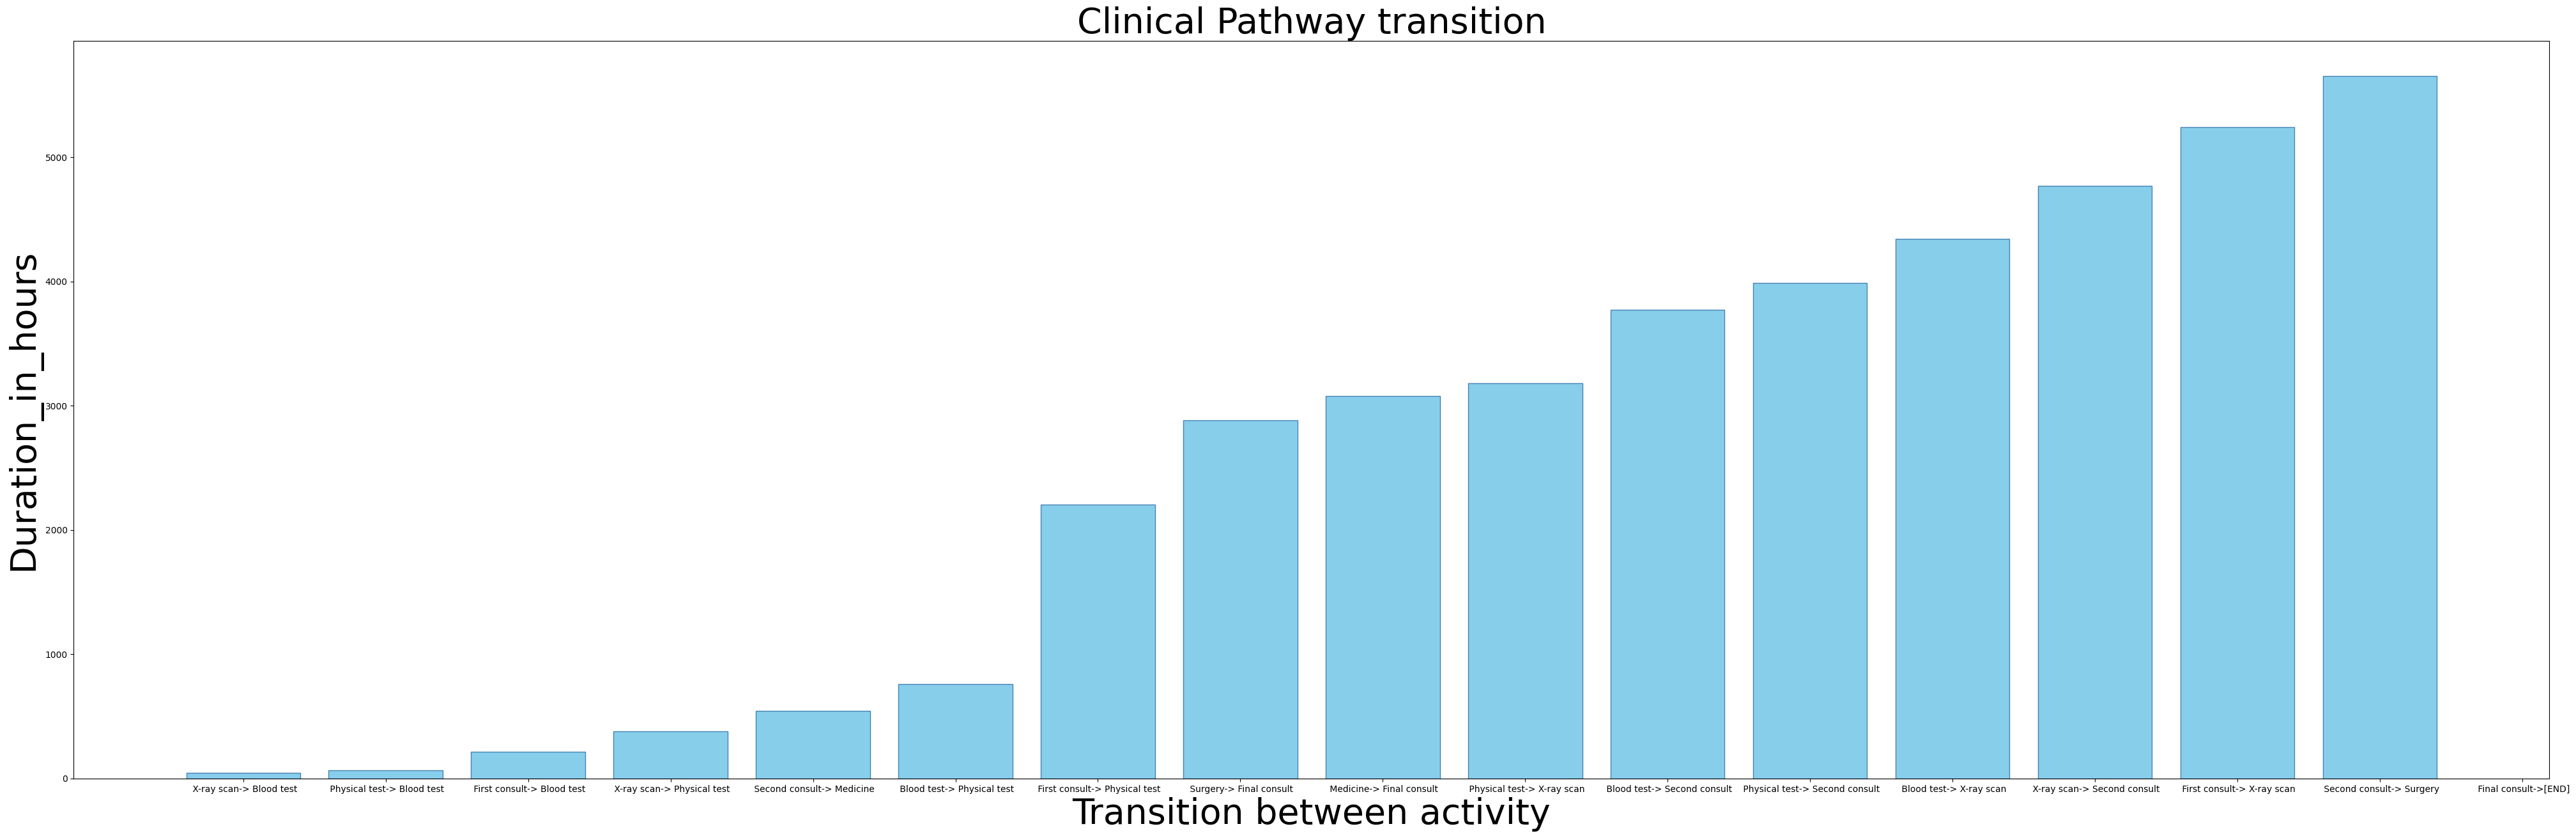

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(50, 15))
plt.bar(bottlecneck_graph['Transition'],bottlecneck_graph['mean'],color='skyblue',edgecolor='steelblue')
plt.xlabel('Transition between activity',color='black',fontsize=40)
plt.ylabel('Duration_in_hours',color='black',fontsize=40)
plt.title("Clinical Pathway transition",fontsize=40,color='black')
plt.show()